# 1. Business Goal and Prediction Point

**Goal:** Identify shipments at risk of arriving late early enough for dispatch to respond.

**Prediction point:** After dispatch, once pickup-delay information is available. `pickup_delay_minutes` is intentionally included because it is known by this decision point. `actual_transit_hours` is recorded on delivery and remains excluded.

**Success priority:** Minimize false negatives (late shipments that the model misses). False alarms are expected to be less costly, but still count them so dispatch can judge the workload.

In [91]:
from pathlib import Path

# Store local history in assignment1 whether the notebook is launched from the repo root or this folder.
MODEL_SCORECARD_PATH = (
    Path('assignment1/.model_scorecard.json')
    if Path('assignment1').is_dir()
    else Path('.model_scorecard.json')
)
HIGH_METRIC_WARNING_THRESHOLD = 0.99

# Enter evidence-based business estimates to enable the optional CAD cost chart.
FALSE_NEGATIVE_COST_CAD = None
FALSE_POSITIVE_COST_CAD = None

# LogisticRegression.predict defaults to 0.5; this is a starting point, not a selected optimum.
ALERT_THRESHOLD = 0.5

In [92]:
import pandas as pd

df_deliveries = pd.read_csv("./maplefreight_delivery_delay_dataset.csv")

df_deliveries

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6030,SHP-101294,London ON,Quebec City QC,QuebecExpress,Standard,Refrigerated,Silver,12,496.9,1150.6,...,70.0,8.3,7.4,Snow,34.5,0.180,0,178.52,8.01,0
6031,SHP-104024,Mississauga ON,Montreal QC,MapleFreight Fleet,Express,Fragile,Bronze,3,1095.3,894.7,...,-19.0,2.4,7.5,Clear,19.5,0.216,1,238.47,17.42,0
6032,SHP-105201,Montreal QC,Toronto ON,MapleFreight Fleet,Standard,Bulk,Gold,2,865.9,1071.0,...,-1.0,19.0,3.2,Clear,61.0,0.470,1,63.29,12.51,0
6033,SHP-103776,Ottawa ON,Quebec City QC,MapleFreight Fleet,Standard,General Freight,Silver,3,776.1,1199.8,...,-7.0,3.2,1.8,Clear,87.7,0.753,3,160.85,10.94,0


## 2. Load and Inspect the Dataset

The dataset contains 6,035 shipments and 23 columns. The target is imbalanced: 4,793 shipments (79.4%) were on time and 1,242 (20.6%) were late. Missing values occur in driver experience (210), weather (150), traffic index (121), and fuel cost (240). The model workflow drops rows with missing weather and imputes the remaining numeric gaps using training-set medians.

In [93]:
print(df_deliveries.shape)

display(df_deliveries.describe())

display(df_deliveries.info())


(6035, 23)


,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
count,6035.000000,6035.000000,6.035000e+03,6035.000000,6035.000000,6035.000000,6035.000000,5825.000000,6035.000000,5914.000000,6035.000000,6035.000000,5795.000000,6035.000000,6035.000000
mean,6.543662,632.192742,6.928251e+03,2.477051,0.113007,10.500388,20.367688,6.497648,5.489461,55.146365,0.449778,1.305551,180.696552,11.186038,0.205800
std,3.448260,319.246133,8.375515e+04,1.707457,0.316628,4.758576,30.618617,4.659277,3.433676,17.592978,0.194500,1.158943,58.759928,5.957114,0.404318
min,1.000000,80.500000,3.000000e+01,0.000000,0.000000,1.000000,-20.000000,0.200000,0.100000,5.000000,0.000000,0.000000,30.000000,0.880000,0.000000
25%,4.000000,398.600000,4.960000e+02,1.000000,0.000000,7.060000,-6.000000,3.200000,3.000000,43.300000,0.318000,0.000000,140.595000,7.080000,0.000000
50%,7.000000,571.100000,8.271000e+02,2.000000,0.000000,9.850000,18.000000,5.400000,4.800000,55.000000,0.446000,1.000000,181.180000,10.050000,0.000000
75%,10.000000,804.850000,1.286300e+03,4.000000,0.000000,13.175000,41.000000,8.600000,7.200000,67.200000,0.583000,2.000000,220.950000,14.010000,0.000000
max,12.000000,2556.700000,2.999300e+06,5.000000,1.000000,37.400000,146.000000,35.000000,20.000000,100.000000,1.000000,8.000000,392.010000,55.380000,1.000000


<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

None

## 3. Data Quality and Cleaning

There are 34 fully duplicated rows in the current dataset. The displayed check compares every column, including `shipment_id`; repeated shipment IDs with other differing fields are a separate uniqueness check. `service_level` casing was normalized to lowercase. Missing weather rows are excluded from modeling; missing numeric predictor values are imputed from the training split. The raw `weight_kg` maximum is 2,999,300 kg versus a median of 827.1 kg, so the extreme value requires source/unit verification. The model clips weight to training-derived 5th and 95th percentiles; clipping does not establish that an input value is correct.

In [94]:
columns = df_deliveries.columns
duplicate_count = df_deliveries[[col for col in columns if col != "shipment_id"]][
    df_deliveries.duplicated() == True
].count()
driver_experience_years_imputed = df_deliveries['driver_experience_years'].isna().sum()
weather_condition_imputed = df_deliveries['weather_condition'].isna().sum()
traffic_index_imputed = df_deliveries['traffic_index'].isna().sum()
fuel_cost_cad_imputed = df_deliveries['fuel_cost_cad'].isna().sum()

print("Dups:", duplicate_count)
print("Exp year Imputed:", driver_experience_years_imputed)
print("weather cond Imputed:", weather_condition_imputed)
print("traffic index Imputed:", traffic_index_imputed)
print("fuel cost cad Imputed:", fuel_cost_cad_imputed)

categorical_columns = df_deliveries.select_dtypes(include='str')
for cat in categorical_columns:
    vals = list(set(df_deliveries[cat]))
    print(cat, vals)

# Normalize service-level casing.
df_deliveries['service_level'] = df_deliveries['service_level'].apply(str.lower)
print(list(set(df_deliveries['service_level'])))

display(df_deliveries[df_deliveries.duplicated()])
display(df_deliveries.isna().sum())
display(df_deliveries.describe())

grouped = df_deliveries.groupby('delivered_late').count()
display(grouped)
not_late = grouped.loc[0]['shipment_id']
late = grouped.loc[1]['shipment_id']
total = not_late + late
print("not late, late, total", not_late, late, total)
print(round(not_late / total, 2) * 100, round(late / total, 2) * 100)

Dups: origin_city                  32
destination_city             32
carrier                      32
service_level                32
goods_type                   32
customer_priority_tier       32
shipment_month               32
distance_km                  32
weight_kg                    32
num_stops                    32
is_cross_border              32
scheduled_transit_hours      32
pickup_delay_minutes         32
driver_experience_years      32
vehicle_age_years            32
weather_condition            32
traffic_index                31
route_congestion_score       32
prior_late_deliveries_30d    32
fuel_cost_cad                32
actual_transit_hours         32
delivered_late               32
dtype: int64
Exp year Imputed: 210
weather cond Imputed: 150
traffic index Imputed: 121
fuel cost cad Imputed: 240
shipment_id ['SHP-100174', 'SHP-101068', 'SHP-100585', 'SHP-100976', 'SHP-101019', 'SHP-103378', 'SHP-101411', 'SHP-100955', 'SHP-101713', 'SHP-105546', 'SHP-100765', 'SHP-102

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
932,SHP-100457,Montreal QC,Toronto ON,PrairieLine,economy,General Freight,Silver,8,532.1,1113.3,...,26.0,20.2,4.6,Clear,66.3,0.691,0,115.19,8.49,0
1443,SHP-103447,Toronto ON,Calgary AB,MapleFreight Fleet,standard,Bulk,Bronze,11,430.5,1018.4,...,5.0,4.9,9.3,Snow,24.2,0.468,3,106.86,10.49,0
2453,SHP-104541,London ON,Ottawa ON,NorthStar Carriers,standard,General Freight,Gold,11,608.8,637.0,...,-1.0,3.1,3.8,Clear,62.7,0.441,1,193.43,8.97,0
2599,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
2920,SHP-101174,London ON,Edmonton AB,MapleFreight Fleet,standard,Refrigerated,Bronze,4,348.2,883.6,...,6.0,12.8,3.1,Clear,65.3,0.420,1,208.64,4.82,0
2956,SHP-103516,Toronto ON,Sudbury ON,PrairieLine,express,General Freight,Gold,10,215.3,603.7,...,9.0,6.1,5.0,Rain,79.3,0.600,1,211.34,7.80,1
3135,SHP-104402,Winnipeg MB,Sudbury ON,NorthStar Carriers,express,Refrigerated,Bronze,7,855.0,1098.4,...,-20.0,3.1,4.4,Storm,NaN,0.713,1,152.77,14.64,0
3184,SHP-101699,Toronto ON,Quebec City QC,QuebecExpress,express,General Freight,Bronze,9,523.3,775.9,...,30.0,10.6,5.5,Clear,75.7,0.636,1,239.41,9.88,0
3188,SHP-105617,Toronto ON,Quebec City QC,MapleFreight Fleet,standard,General Freight,Silver,12,465.2,928.4,...,4.0,3.8,3.8,Fog,69.2,0.612,1,197.80,9.61,0
3583,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0


shipment_id                    0
origin_city                    0
destination_city               0
carrier                        0
service_level                  0
goods_type                     0
customer_priority_tier         0
shipment_month                 0
distance_km                    0
weight_kg                      0
num_stops                      0
is_cross_border                0
scheduled_transit_hours        0
pickup_delay_minutes           0
driver_experience_years      210
vehicle_age_years              0
weather_condition            150
traffic_index                121
route_congestion_score         0
prior_late_deliveries_30d      0
fuel_cost_cad                240
actual_transit_hours           0
delivered_late                 0
dtype: int64

,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
count,6035.000000,6035.000000,6.035000e+03,6035.000000,6035.000000,6035.000000,6035.000000,5825.000000,6035.000000,5914.000000,6035.000000,6035.000000,5795.000000,6035.000000,6035.000000
mean,6.543662,632.192742,6.928251e+03,2.477051,0.113007,10.500388,20.367688,6.497648,5.489461,55.146365,0.449778,1.305551,180.696552,11.186038,0.205800
std,3.448260,319.246133,8.375515e+04,1.707457,0.316628,4.758576,30.618617,4.659277,3.433676,17.592978,0.194500,1.158943,58.759928,5.957114,0.404318
min,1.000000,80.500000,3.000000e+01,0.000000,0.000000,1.000000,-20.000000,0.200000,0.100000,5.000000,0.000000,0.000000,30.000000,0.880000,0.000000
25%,4.000000,398.600000,4.960000e+02,1.000000,0.000000,7.060000,-6.000000,3.200000,3.000000,43.300000,0.318000,0.000000,140.595000,7.080000,0.000000
50%,7.000000,571.100000,8.271000e+02,2.000000,0.000000,9.850000,18.000000,5.400000,4.800000,55.000000,0.446000,1.000000,181.180000,10.050000,0.000000
75%,10.000000,804.850000,1.286300e+03,4.000000,0.000000,13.175000,41.000000,8.600000,7.200000,67.200000,0.583000,2.000000,220.950000,14.010000,0.000000
max,12.000000,2556.700000,2.999300e+06,5.000000,1.000000,37.400000,146.000000,35.000000,20.000000,100.000000,1.000000,8.000000,392.010000,55.380000,1.000000


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours
delivered_late,,,,,,,,,,,,,,,,,,,,,
0,4793,4793,4793,4793,4793,4793,4793,4793,4793,4793,...,4793,4793,4630,4793,4676,4694,4793,4793,4599,4793
1,1242,1242,1242,1242,1242,1242,1242,1242,1242,1242,...,1242,1242,1195,1242,1209,1220,1242,1242,1196,1242


not late, late, total 4793 1242 6035
79.0 21.0


## 4. Exploratory Data Analysis

After excluding 150 records with missing weather, 5,885 shipments remain: 4,676 on time and 1,209 late (20.5% late). In the dispatch-time numeric predictor heatmap, distance and scheduled transit time show a clear positive association; most other predictor pairs are comparatively weak. The raw weight distribution is extremely right-skewed: its median is 827.1 kg, while the maximum is 2,999,300 kg. The visualization copy is clipped at its 5th and 95th percentiles to make the central distribution visible; this is a visualization aid, not evidence that the extreme record is valid. The model applies separate clipping bounds estimated from its training split.

Kurtosis 421.01601517961336
lower %5 206.94
lower %95 2244.5700000000006


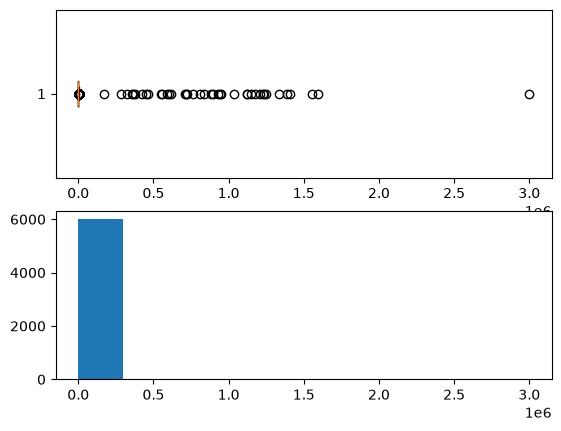

In [95]:
import matplotlib.pyplot as plt

df_copy = df_deliveries.copy()
numerical_columns = [column for column in df_copy.columns if column not in df_copy.select_dtypes(include="str")]
# print(numerical_columns we found that weight kg might be the outlier fille done)
fig, axs = plt.subplots(2,1)


axs[0].boxplot(df_copy['weight_kg'], orientation="horizontal")

axs[1].hist(df_copy['weight_kg'])
# Let's remove outliers
tenth_percentile_weight = df_copy['weight_kg'].quantile(.05)
ninety_percentile_weight = df_copy['weight_kg'].quantile(.95)

print("Kurtosis", df_copy['weight_kg'].kurt())
print("lower %5", tenth_percentile_weight)
print("lower %95", ninety_percentile_weight)

Kurtosis -0.3039972634462704
lower %5 206.982
lower %95 2243.7510000000007


(array([1117.,  940.,  908.,  799.,  613.,  459.,  340.,  238.,  191.,
         430.]),
 array([ 206.94 ,  410.703,  614.466,  818.229, 1021.992, 1225.755,
        1429.518, 1633.281, 1837.044, 2040.807, 2244.57 ]),
 <BarContainer object of 10 artists>)

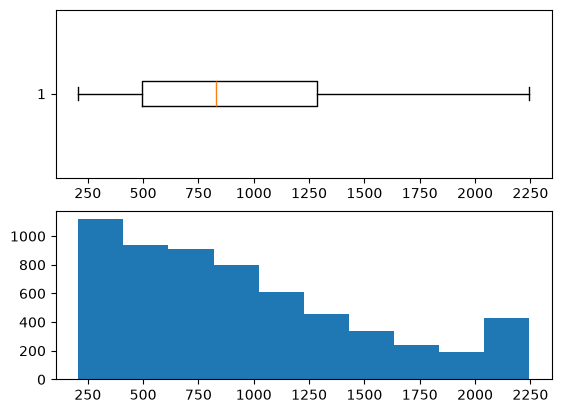

In [96]:
# df_copy['weight_kg'] = mstats.winsorize(df_deliveries['weight_kg'],limits(0.10,0.1))
## there are some impomssible weights like 2,999,300; might be mistake of input and is actually 2,999.30? so clipping to our max
df_copy['weight_kg'] = df_copy['weight_kg'].clip(lower=tenth_percentile_weight,upper=ninety_percentile_weight)

print("Kurtosis", df_copy['weight_kg'].kurt())
print("lower %5",df_copy['weight_kg'].quantile(.05))
print("lower %95",df_copy['weight_kg'].quantile(.95))

fig, axs = plt.subplots(2,1)
axs[0].boxplot(df_copy['weight_kg'], orientation="horizontal")
axs[1].hist(df_copy['weight_kg'])

### Numeric Relationships and Class Distributions

The heatmap uses a fixed Pearson-correlation scale from -1 to +1, so an extreme correlation would not rescale the colors of other cells. However, `actual_transit_hours` is recorded after delivery and is not an eligible predictor; the deployment-focused heatmap therefore excludes it and the target. The remaining chart shows pairwise relationships among numeric features available at dispatch. Correlation is linear association, not causation. The grouped summaries compare numeric feature distributions for on-time and late shipments; differences are descriptive and do not establish that a feature causes delay.

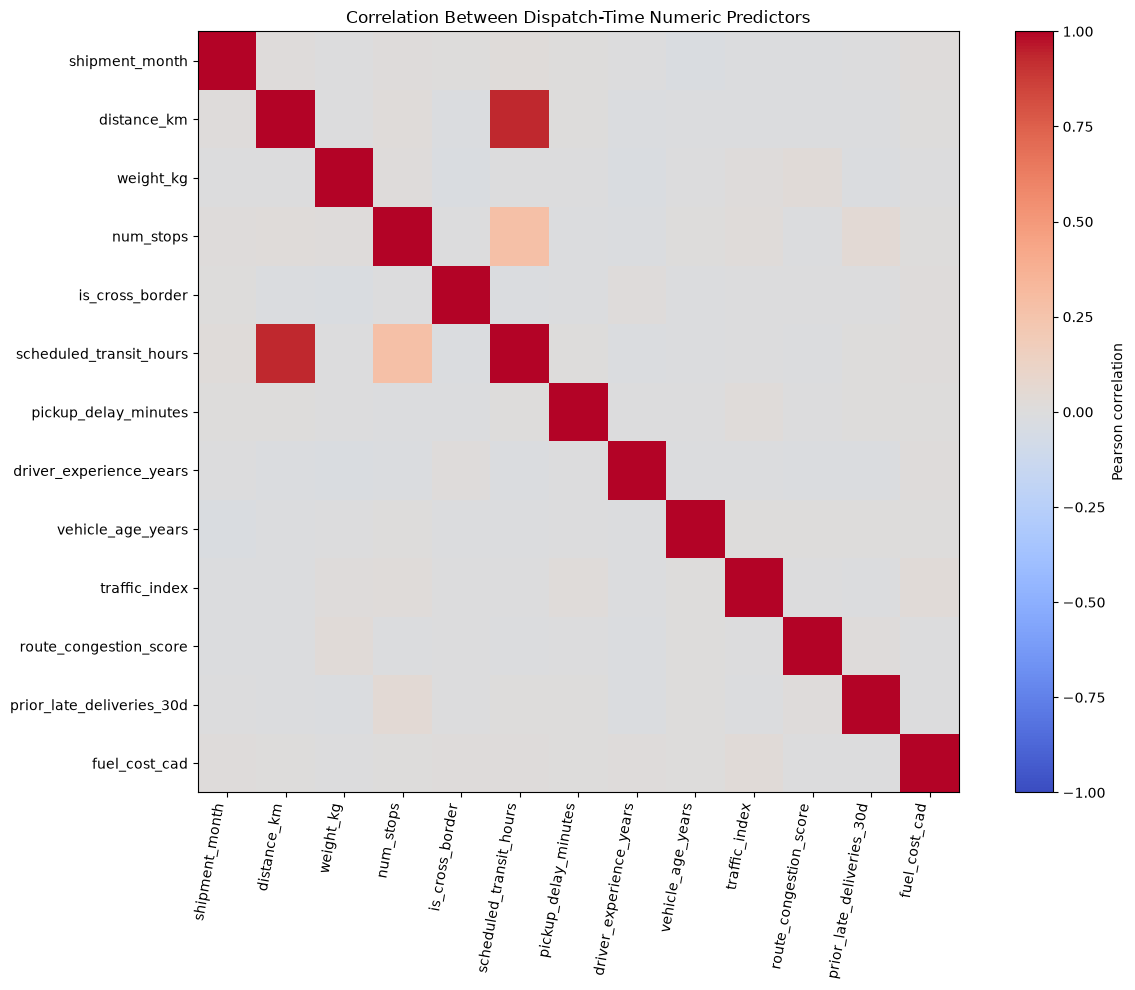

shipment_month                                         \
                        count  mean   std  min  25%  50%   75%   max   
delivered_late                                                         
0                      4793.0  6.59  3.42  1.0  4.0  7.0  10.0  12.0   
1                      1242.0  6.37  3.56  1.0  3.0  6.0   9.0  12.0   

               distance_km          ... prior_late_deliveries_30d       \
                     count    mean  ...                       75%  max   
delivered_late                      ...                                  
0                   4793.0  602.27  ...                       2.0  8.0   
1                   1242.0  747.67  ...                       2.0  7.0   

               fuel_cost_cad                                               \
                       count    mean    std   min     25%     50%     75%   
delivered_late                                                              
0                     4599.0  180.45  59.02  30.0  140.02  180.64  220.55   
1                     1196.0  181.64  57.78  30.0  144.08  183.46  222.36   

                        
                   max  
delivered_late          
0               392.01  
1               343.29  

[2 rows x 104 columns]

In [97]:
numeric_columns_eda = df_deliveries.select_dtypes(include='number').columns
numeric_predictors_eda = numeric_columns_eda.drop(
    ['delivered_late', 'actual_transit_hours'],
    errors='ignore',
)
correlation_matrix = df_deliveries[numeric_predictors_eda].corr()

fig, ax = plt.subplots(figsize=(13, 10))
heatmap = ax.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_predictors_eda)))
ax.set_xticklabels(numeric_predictors_eda, rotation=80, ha='right')
ax.set_yticks(range(len(numeric_predictors_eda)))
ax.set_yticklabels(numeric_predictors_eda)
ax.set_title('Correlation Between Dispatch-Time Numeric Predictors')
fig.colorbar(heatmap, ax=ax, label='Pearson correlation')
fig.tight_layout()
plt.show()

class_distribution_summary = df_deliveries.groupby('delivered_late')[numeric_predictors_eda].describe(
    percentiles=[0.25, 0.5, 0.75]
).round(2)
display(class_distribution_summary)

# Class Notes: Preprocessing and Model Concepts

## Missing data and outliers

- Imputation replaces missing values using a documented rule.
- Z-scores and the interquartile range (IQR) can help flag unusual values. A flagged value is not automatically an error; check its units and domain plausibility first.
- Skewness describes asymmetry; kurtosis describes tail weight. Neither statistic alone proves that a value is invalid.

## Feature scaling

- **Min-max scaling:** $x' = (x - x_{min}) / (x_{max} - x_{min})$. This maps values to a fixed range, usually $[0, 1]$, but is sensitive to extreme values.
- **Standardization:** $z = (x - \mu) / \sigma$. This centers a feature and scales it to unit standard deviation; it does not remove or neutralize outliers.

## EDA and explainability

- EDA goals: inspect distributions, relationships, target balance, and unusual values to identify useful questions.
- SHAP is one approach to explaining individual predictions and overall feature effects.
- Decision trees can use entropy/information gain or Gini impurity to choose splits; tree-based models also provide feature-importance measures.
- Random forests combine many trees. Gradient boosting builds trees sequentially to improve earlier predictions.
- XGBoost, LightGBM, and CatBoost are gradient-boosting libraries with different performance and feature-handling trade-offs.

## 5. Feature-Engineering Hypotheses to Test

These hypotheses are separate from the fitted models above and were not evaluated in this run. They are candidate transformations to test using training/validation data, one at a time, against the same baseline. Preserve the test set for final evaluation.

- **Required route speed:** `distance_km / scheduled_transit_hours` (km/h). Test whether planned speed adds information beyond distance and scheduled time.
- **Fuel intensity:** `fuel_cost_cad / distance_km` (CAD/km). Test whether cost per kilometre adds information beyond its source features.
- **Stop density:** `num_stops / distance_km * 100` (stops per 100 km). Test whether route stop density relates to delay risk.
- **Congestion interaction:** `traffic_index * route_congestion_score`. Test whether current traffic has a different association on historically congested routes.

For each experiment, state the hypothesis, expected direction, validation result, and whether the change improves the metric that matters operationally. An observed association is not evidence of causation.

## 6. Historical Model: Leakage Demonstration Only

This deliberately invalid comparison demonstrates two evaluation risks: imputing with statistics calculated on the full dataset before splitting, and using `actual_transit_hours`, which is only known after delivery. It also uses an unstratified split. Its near-perfect metrics are an illustration of leakage, not evidence of a usable model, and must not be compared with or reported alongside the valid candidates.

In [98]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

In [99]:
# Intentionally invalid demonstration: full-data imputation and post-outcome leakage.
df_historical = df_deliveries.copy()
df_historical.dropna(subset=['weather_condition'], inplace=True)

for column in ['driver_experience_years', 'traffic_index', 'fuel_cost_cad']:
    df_historical[column] = df_historical[column].fillna(df_historical[column].median())

y_historical = df_historical['delivered_late']
X_historical = df_historical.drop(['delivered_late', 'shipment_id'], axis=1)

X_train_historical, X_test_historical, y_train_historical, y_test_historical = train_test_split(
    X_historical, y_historical, test_size=0.2, random_state=67
)

categorical_historical = X_train_historical.select_dtypes(include='str').columns
encoder_historical = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_historical = encoder_historical.fit_transform(X_train_historical[categorical_historical])
encoded_historical_df = pd.DataFrame(
    encoded_historical,
    columns=encoder_historical.get_feature_names_out(),
    index=X_train_historical.index,
)
numerical_historical = [
    column for column in X_train_historical.columns
    if column not in categorical_historical
]
X_train_historical = pd.concat(
    [X_train_historical[numerical_historical], encoded_historical_df], axis=1
)

encoded_historical_test = encoder_historical.transform(X_test_historical[categorical_historical])
encoded_historical_test_df = pd.DataFrame(
    encoded_historical_test,
    columns=encoder_historical.get_feature_names_out(),
    index=X_test_historical.index,
)
X_test_historical = pd.concat(
    [X_test_historical[numerical_historical], encoded_historical_test_df], axis=1
)

model_historical = LogisticRegression(class_weight='balanced', max_iter=1000)
model_historical.fit(X_train_historical, y_train_historical)
y_pred_historical = model_historical.predict(X_test_historical)

historical_precision, historical_recall, historical_f1, _ = precision_recall_fscore_support(
    y_test_historical, y_pred_historical, average='weighted'
)
print('Historical leakage demonstration only')
print('Weighted precision:', historical_precision)
print('Weighted recall:', historical_recall)
print('Weighted F1:', historical_f1)
print('Confusion matrix:')
print(confusion_matrix(y_test_historical, y_pred_historical, labels=[0, 1]))

Historical leakage demonstration only
Weighted precision: 0.9991537405005693
Weighted recall: 0.9991503823279524
Weighted F1: 0.999150993782981
Confusion matrix:
[[924   1]
 [  0 252]]


/home/alejandro-parparcen/Documents/Lambton/2026/Fall/Software-Tools-AML-3303/repos/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 7. Preprocessing and Balanced Logistic Regression

This model predicts after pickup, using `pickup_delay_minutes` and other features available at that point. It excludes `actual_transit_hours`, drops rows with missing weather, uses a stratified 80/20 split, and learns imputation and weight-clipping values from training data. Numeric features are standardized and categorical features are one-hot encoded before fitting balanced logistic regression. The held-out split is used for the exploratory comparisons below.

Weighted precision: 0.8217696026595621
Weighted recall: 0.7476635514018691
Weighted F1: 0.768371591651973
Confusion matrix [actual rows, predicted columns]:
[[697 238]
 [ 59 183]]
ROC AUC: 0.822


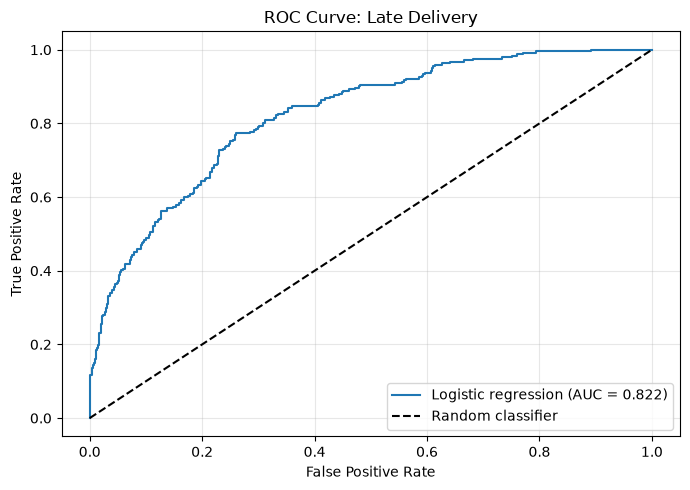

In [100]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support,confusion_matrix, roc_auc_score,roc_curve
from sklearn.preprocessing import StandardScaler

df_deliveries.dropna(subset=['weather_condition'],inplace=True)

y = df_deliveries['delivered_late']
X = df_deliveries.drop(['delivered_late','shipment_id','actual_transit_hours'], axis=1)


#We stratify because we want to retain same proportions
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size=.2,stratify=y, random_state=67)

# feat eng?
train_traffic_index_median=X_train['traffic_index'].median()
train_fuel_cost_cad_median=X_train['fuel_cost_cad'].median()
train_driver_experience_years_median = X_train['driver_experience_years'].median()

X_train['driver_experience_years']=X_train['driver_experience_years'].fillna(train_driver_experience_years_median)
X_train['traffic_index']=X_train['traffic_index'].fillna(train_traffic_index_median)
X_train['fuel_cost_cad']=X_train['fuel_cost_cad'].fillna(train_fuel_cost_cad_median)

X_test['driver_experience_years']=X_test['driver_experience_years'].fillna(train_driver_experience_years_median)
X_test['traffic_index']=X_test['traffic_index'].fillna(train_traffic_index_median)#X_test['traffic_index'].median())
X_test['fuel_cost_cad']=X_test['fuel_cost_cad'].fillna(train_fuel_cost_cad_median)#X_test['fuel_cost_cad'].median())

# NEW FEAT ENG


categorical_columns = X_train.select_dtypes(include='str').columns
numerical_columns = [column for column in X_train.columns if column not in categorical_columns]

# Winsorization of training data
train_weight_lower_bound = X_train['weight_kg'].quantile(.05)
train_weight_upper_bound = X_train['weight_kg'].quantile(.95)
X_train['weight_kg'] = X_train['weight_kg'].clip(lower=train_weight_lower_bound,upper=train_weight_upper_bound)

# Winsorization of test data
# train_weight_lower_bound = X_test['weight_kg'].quantile(.05)
# train_weight_upper_bound = X_test['weight_kg'].quantile(.95)
X_test['weight_kg'] = X_test['weight_kg'].clip(lower=train_weight_lower_bound,upper=train_weight_upper_bound)

# scaling
scaler = StandardScaler()

X_train[numerical_columns] = scaler.fit_transform(X_train[numerical_columns])
X_test[numerical_columns] = scaler.transform(X_test[numerical_columns])


encoder = OneHotEncoder(sparse_output=False)
# print([list(set(df_deliveries[delivery])) 
#        for delivery 
#        in categorical_columns])
# print(categorical_columns)

encoded_data = encoder.fit_transform(X_train[categorical_columns], y_train)

df_encoded = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(),
    index=X_train.index)

# print(numerical_columns)
X_train = pd.concat([
    X_train[numerical_columns],
    df_encoded
],axis=1)

# print(X_train)

lr = LogisticRegression(class_weight='balanced',max_iter=1000)

model = lr.fit(X_train,y_train)

encoded_data = encoder.transform(X_test[categorical_columns])

df_encoded = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(),
    index=X_test.index
)

X_test = pd.concat([X_test[numerical_columns], df_encoded], 
    axis=1
)




# display(df_encoded)
y_pred = model.predict(X_test)

precision, recall, fscore, support = precision_recall_fscore_support(y_test, y_pred, average="weighted")

print('Weighted precision:', precision)
print('Weighted recall:', recall)
print('Weighted F1:', fscore)
print('Confusion matrix [actual rows, predicted columns]:')
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

y_score = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = roc_auc_score(y_test, y_score)
print(f'ROC AUC: {roc_auc:.3f}')

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Late Delivery')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Compare Class-Weight Choices on the Same Split

The unweighted and balanced logistic-regression models use the same prepared training and test matrices. The comparison isolates the effect of class weighting. Balanced weighting increases late-class recall at the default 0.5 cutoff, while unweighted logistic regression has higher late-class precision and fewer false alerts. These are threshold-dependent trade-offs on one held-out split.

,model,weighted_precision,weighted_recall,weighted_f1,late_precision,late_recall,late_f1,roc_auc
0,Logistic regression (unweighted),0.818,0.834,0.814,0.682,0.364,0.474,0.820
1,Logistic regression (balanced),0.822,0.748,0.768,0.435,0.756,0.552,0.822


Unweighted confusion matrix [actual rows, predicted columns]:
[[894  41]
 [154  88]]


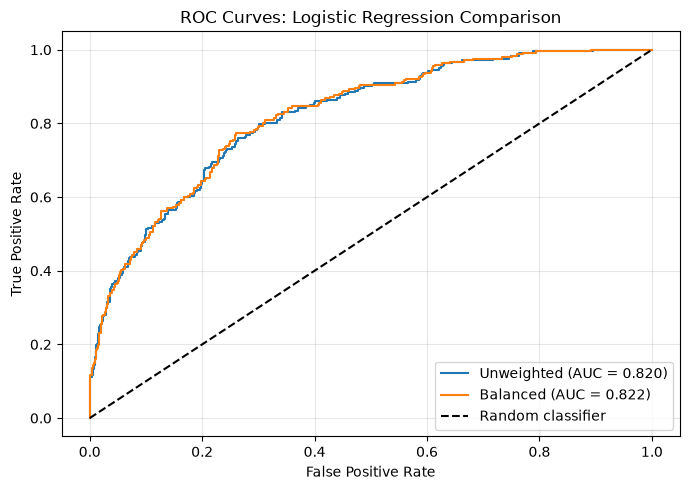

In [101]:
model_unweighted = LogisticRegression(max_iter=1000)
model_unweighted.fit(X_train, y_train)
y_pred_unweighted = model_unweighted.predict(X_test)
y_score_unweighted = model_unweighted.predict_proba(X_test)[:, 1]

unweighted_precision, unweighted_recall, unweighted_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_unweighted, average='weighted'
)
unweighted_class_precision, unweighted_class_recall, unweighted_class_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_unweighted, average=None, labels=[0, 1]
)
balanced_precision, balanced_recall, balanced_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average='weighted'
)
balanced_class_precision, balanced_class_recall, balanced_class_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average=None, labels=[0, 1]
)
unweighted_auc = roc_auc_score(y_test, y_score_unweighted)

model_comparison = pd.DataFrame([
    {
        'model': 'Logistic regression (unweighted)',
        'weighted_precision': unweighted_precision,
        'weighted_recall': unweighted_recall,
        'weighted_f1': unweighted_f1,
        'late_precision': unweighted_class_precision[1],
        'late_recall': unweighted_class_recall[1],
        'late_f1': unweighted_class_f1[1],
        'roc_auc': unweighted_auc,
    },
    {
        'model': 'Logistic regression (balanced)',
        'weighted_precision': balanced_precision,
        'weighted_recall': balanced_recall,
        'weighted_f1': balanced_f1,
        'late_precision': balanced_class_precision[1],
        'late_recall': balanced_class_recall[1],
        'late_f1': balanced_class_f1[1],
        'roc_auc': roc_auc,
    },
])
display(model_comparison.round(3))

print('Unweighted confusion matrix [actual rows, predicted columns]:')
print(confusion_matrix(y_test, y_pred_unweighted, labels=[0, 1]))

fpr_unweighted, tpr_unweighted, _ = roc_curve(y_test, y_score_unweighted)
plt.figure(figsize=(7, 5))
plt.plot(fpr_unweighted, tpr_unweighted, label=f'Unweighted (AUC = {unweighted_auc:.3f})')
plt.plot(fpr, tpr, label=f'Balanced (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Logistic Regression Comparison')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Majority Baseline and SMOTENC Comparison

The majority-class `DummyClassifier` provides a no-skill reference. SMOTENC resamples only the training data and handles categorical columns before one-hot encoding; the held-out test data remains unchanged. On this split, balanced logistic regression has higher late-class recall and ROC AUC than SMOTENC. Compare missed delays and false alerts as well as the aggregate scores.

,model,weighted_precision,weighted_recall,weighted_f1,late_precision,late_recall,late_f1,roc_auc
1,Logistic regression (balanced),0.822,0.748,0.768,0.435,0.756,0.552,0.822
3,Logistic regression (SMOTENC),0.791,0.715,0.738,0.388,0.674,0.492,0.789
0,Logistic regression (unweighted),0.818,0.834,0.814,0.682,0.364,0.474,0.820
2,Majority-class baseline,0.631,0.794,0.703,0.000,0.000,0.000,0.500


SMOTENC confusion matrix [actual rows, predicted columns]:
[[678 257]
 [ 79 163]]


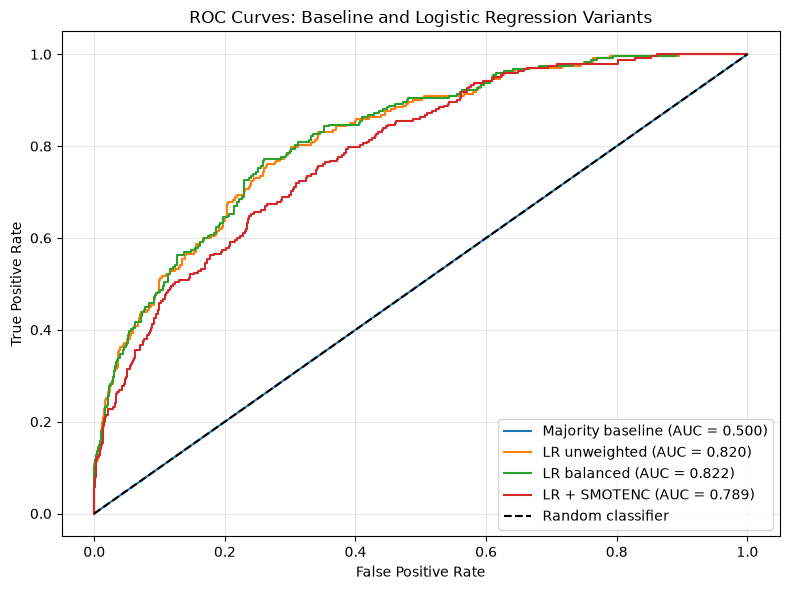

In [102]:
from imblearn.over_sampling import SMOTENC
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)
y_score_baseline = baseline_model.predict_proba(X_test)[:, 1]

# Rebuild the mixed-type training features before one-hot encoding for SMOTENC.
X_train_smote_source = X.loc[X_train.index].copy()
train_medians = {
    'driver_experience_years': train_driver_experience_years_median,
    'traffic_index': train_traffic_index_median,
    'fuel_cost_cad': train_fuel_cost_cad_median,
}
for column, median_value in train_medians.items():
    X_train_smote_source[column] = X_train_smote_source[column].fillna(median_value)

X_train_smote_source['weight_kg'] = X_train_smote_source['weight_kg'].clip(
    lower=train_weight_lower_bound,
    upper=train_weight_upper_bound,
)
X_train_smote_source[numerical_columns] = scaler.transform(
    X_train_smote_source[numerical_columns]
)

smotenc = SMOTENC(categorical_features=list(categorical_columns), random_state=67)
X_train_smote, y_train_smote = smotenc.fit_resample(X_train_smote_source, y_train)
encoded_smote = encoder.transform(X_train_smote[categorical_columns])
encoded_smote_df = pd.DataFrame(
    encoded_smote,
    columns=encoder.get_feature_names_out(),
    index=X_train_smote.index,
)
X_train_smote_model = pd.concat(
    [X_train_smote[numerical_columns], encoded_smote_df], axis=1
)

model_smotenc = LogisticRegression(max_iter=1000)
model_smotenc.fit(X_train_smote_model, y_train_smote)
y_pred_smotenc = model_smotenc.predict(X_test)
y_score_smotenc = model_smotenc.predict_proba(X_test)[:, 1]

baseline_class_precision, baseline_class_recall, baseline_class_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_baseline, average=None, labels=[0, 1], zero_division=0
)
smotenc_precision, smotenc_recall, smotenc_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_smotenc, average='weighted'
)
smotenc_class_precision, smotenc_class_recall, smotenc_class_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_smotenc, average=None, labels=[0, 1], zero_division=0
)
baseline_precision, baseline_recall, baseline_f1, _ = precision_recall_fscore_support(
    y_test, y_pred_baseline, average='weighted', zero_division=0
)

additional_models = pd.DataFrame([
    {
        'model': 'Majority-class baseline',
        'weighted_precision': baseline_precision,
        'weighted_recall': baseline_recall,
        'weighted_f1': baseline_f1,
        'late_precision': baseline_class_precision[1],
        'late_recall': baseline_class_recall[1],
        'late_f1': baseline_class_f1[1],
        'roc_auc': roc_auc_score(y_test, y_score_baseline),
    },
    {
        'model': 'Logistic regression (SMOTENC)',
        'weighted_precision': smotenc_precision,
        'weighted_recall': smotenc_recall,
        'weighted_f1': smotenc_f1,
        'late_precision': smotenc_class_precision[1],
        'late_recall': smotenc_class_recall[1],
        'late_f1': smotenc_class_f1[1],
        'roc_auc': roc_auc_score(y_test, y_score_smotenc),
    },
])
model_comparison = pd.concat([model_comparison, additional_models], ignore_index=True)
model_comparison = model_comparison.sort_values('late_recall', ascending=False)
display(model_comparison.round(3))

print('SMOTENC confusion matrix [actual rows, predicted columns]:')
print(confusion_matrix(y_test, y_pred_smotenc, labels=[0, 1]))

fpr_baseline, tpr_baseline, _ = roc_curve(y_test, y_score_baseline)
fpr_smotenc, tpr_smotenc, _ = roc_curve(y_test, y_score_smotenc)
plt.figure(figsize=(8, 6))
plt.plot(fpr_baseline, tpr_baseline, label=f'Majority baseline (AUC = {roc_auc_score(y_test, y_score_baseline):.3f})')
plt.plot(fpr_unweighted, tpr_unweighted, label=f'LR unweighted (AUC = {unweighted_auc:.3f})')
plt.plot(fpr, tpr, label=f'LR balanced (AUC = {roc_auc:.3f})')
plt.plot(fpr_smotenc, tpr_smotenc, label=f'LR + SMOTENC (AUC = {roc_auc_score(y_test, y_score_smotenc):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves: Baseline and Logistic Regression Variants')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Threshold, Confusion Errors, and Cost Scenarios

ROC AUC (`0.822`) measures how well the model ranks late shipments above on-time shipments; it is not a decision threshold. The standard `0.50` cutoff is retained as a starting-point comparison.

For the pilot alert, five-fold out-of-fold predictions on the training partition select a cutoff by maximizing late-class F2 (`beta=2`, which weights recall more than precision), subject to late-class precision of at least `0.50`. This precision floor is a transparent initial workload guardrail, not a measured dispatch-capacity or dollar-cost limit. Imputation, weight clipping, scaling, and encoding are refit inside each fold. The selected cutoff is `0.65` (validation precision `0.530`, recall `0.571`, F2 `0.562`).

The `0.65` cutoff is evaluated once on the held-out test split: precision `0.525`, recall `0.562`, with 136 late shipments caught, 106 missed, and 123 false alerts (confusion matrix `[[812, 123], [106, 136]]`). The test split is not used to select the cutoff. These results are from one random split and make `0.65` a provisional pilot choice, not a production setting. The dataset contains no agreed cost for a missed delay or false alert, so the optional CAD chart remains disabled until evidence-based estimates are supplied.

Standard starting cutoff: 0.50
Validation-selected pilot cutoff: 0.65 (late precision=0.533, late recall=0.571, F2=0.563; precision floor=0.50)


,probability_threshold,late_precision,late_recall,late_f2
0,0.10,0.236,0.987,0.603
1,0.15,0.257,0.970,0.623
2,0.20,0.275,0.951,0.638
3,0.25,0.296,0.923,0.649
4,0.30,0.318,0.887,0.653
5,0.35,0.341,0.856,0.657
6,0.40,0.368,0.816,0.656
7,0.45,0.393,0.775,0.649
8,0.50,0.426,0.725,0.636
9,0.55,0.459,0.674,0.617


,probability_threshold,late_precision,late_recall,late_f1,true_positives,false_negatives,false_positives
0,0.10,0.239,0.996,0.385,241,1,768
1,0.15,0.257,0.975,0.407,236,6,682
2,0.20,0.284,0.963,0.438,233,9,588
3,0.25,0.299,0.909,0.450,220,22,516
4,0.30,0.329,0.893,0.481,216,26,441
5,0.35,0.348,0.864,0.496,209,33,391
6,0.40,0.382,0.843,0.526,204,38,330
7,0.45,0.401,0.793,0.533,192,50,287
8,0.50,0.435,0.756,0.552,183,59,238
9,0.55,0.444,0.661,0.532,160,82,200


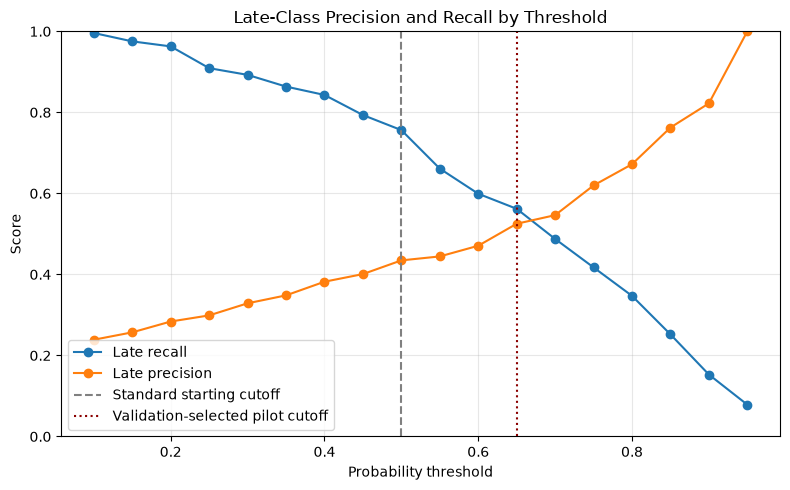

,false_negatives,false_positives
model,,
Majority baseline,242,0
LR unweighted,154,41
LR balanced,59,238
LR + SMOTENC,79,257


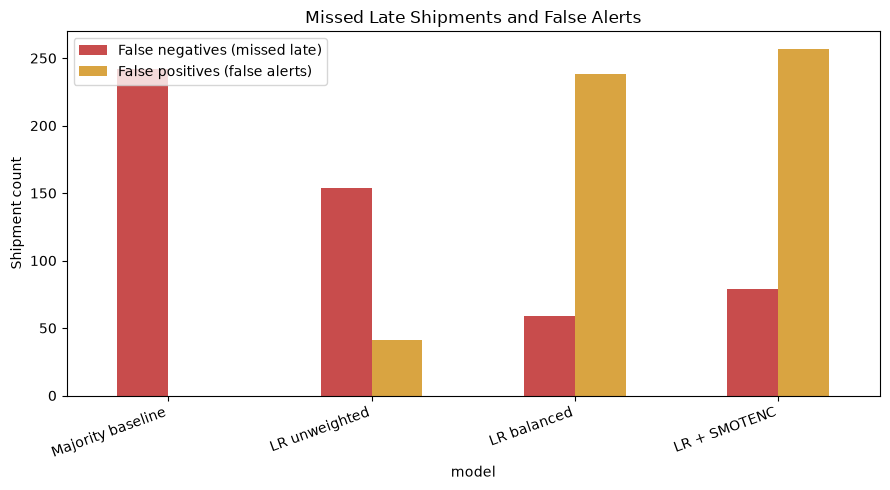

CAD cost chart skipped: enter agreed false-negative and false-positive costs in the configuration cell.


In [103]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

STARTING_ALERT_THRESHOLD = ALERT_THRESHOLD
VALIDATION_PRECISION_FLOOR = 0.50
threshold_grid = [cutoff / 100 for cutoff in range(10, 96, 5)]
X_train_raw = X.loc[X_train.index]
categorical_columns_raw = X_train_raw.select_dtypes(include='str').columns.tolist()
numerical_columns_raw = [column for column in X_train_raw.columns if column not in categorical_columns_raw]


class WeightQuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, weight_index, lower_quantile=0.05, upper_quantile=0.95):
        self.weight_index = weight_index
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, values, target=None):
        weight_values = np.asarray(values)[:, self.weight_index]
        self.lower_bound_ = np.quantile(weight_values, self.lower_quantile)
        self.upper_bound_ = np.quantile(weight_values, self.upper_quantile)
        return self

    def transform(self, values):
        clipped_values = np.asarray(values).copy()
        clipped_values[:, self.weight_index] = np.clip(
            clipped_values[:, self.weight_index],
            self.lower_bound_,
            self.upper_bound_,
        )
        return clipped_values


numeric_validation_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('weight_clip', WeightQuantileClipper(numerical_columns_raw.index('weight_kg'))),
    ('scaler', StandardScaler()),
])
categorical_validation_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore')),
])
validation_preprocessor = ColumnTransformer([
    ('numeric', numeric_validation_pipeline, numerical_columns_raw),
    ('categorical', categorical_validation_pipeline, categorical_columns_raw),
])
validation_model = Pipeline([
    ('preprocessor', validation_preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000)),
])
validation_scores = cross_val_predict(
    validation_model,
    X_train_raw,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=67),
    method='predict_proba',
)[:, 1]

validation_rows = []
for threshold in threshold_grid:
    validation_predictions = (validation_scores >= threshold).astype(int)
    late_precision, late_recall, _, _ = precision_recall_fscore_support(
        y_train,
        validation_predictions,
        average='binary',
        pos_label=1,
        zero_division=0,
    )
    late_f2 = (
        5 * late_precision * late_recall / (4 * late_precision + late_recall)
        if 4 * late_precision + late_recall > 0
        else 0
    )
    validation_rows.append({
        'probability_threshold': threshold,
        'late_precision': late_precision,
        'late_recall': late_recall,
        'late_f2': late_f2,
    })

validation_threshold_results = pd.DataFrame(validation_rows)
eligible_thresholds = validation_threshold_results[
    validation_threshold_results['late_precision'] >= VALIDATION_PRECISION_FLOOR
]
if eligible_thresholds.empty:
    raise ValueError('No validation threshold meets the late-class precision floor.')

selected_threshold_row = eligible_thresholds.sort_values(
    ['late_f2', 'late_precision', 'late_recall'],
    ascending=False,
).iloc[0]
ALERT_THRESHOLD = float(selected_threshold_row['probability_threshold'])
print(f'Standard starting cutoff: {STARTING_ALERT_THRESHOLD:.2f}')
print(
    f'Validation-selected pilot cutoff: {ALERT_THRESHOLD:.2f} '
    f'(late precision={selected_threshold_row["late_precision"]:.3f}, '
    f'late recall={selected_threshold_row["late_recall"]:.3f}, '
    f'F2={selected_threshold_row["late_f2"]:.3f}; '
    f'precision floor={VALIDATION_PRECISION_FLOOR:.2f})'
)

display(validation_threshold_results.round(3))

threshold_grid = sorted(set(threshold_grid) | {STARTING_ALERT_THRESHOLD, ALERT_THRESHOLD})
threshold_rows = []
for threshold in threshold_grid:
    y_pred_at_threshold = (y_score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_at_threshold, labels=[0, 1]).ravel()
    late_precision, late_recall, late_f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred_at_threshold,
        average='binary',
        pos_label=1,
        zero_division=0,
    )
    threshold_rows.append({
        'probability_threshold': threshold,
        'late_precision': late_precision,
        'late_recall': late_recall,
        'late_f1': late_f1,
        'true_positives': tp,
        'false_negatives': fn,
        'false_positives': fp,
    })
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    threshold_results['probability_threshold'],
    threshold_results['late_recall'],
    marker='o',
    label='Late recall',
)
ax.plot(
    threshold_results['probability_threshold'],
    threshold_results['late_precision'],
    marker='o',
    label='Late precision',
)
ax.axvline(STARTING_ALERT_THRESHOLD, color='gray', linestyle='--', label='Standard starting cutoff')
ax.axvline(ALERT_THRESHOLD, color='darkred', linestyle=':', label='Validation-selected pilot cutoff')
ax.set_xlabel('Probability threshold')
ax.set_ylabel('Score')
ax.set_title('Late-Class Precision and Recall by Threshold')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

predictions_by_model = {
    'Majority baseline': y_pred_baseline,
    'LR unweighted': y_pred_unweighted,
    'LR balanced': y_pred,
    'LR + SMOTENC': y_pred_smotenc,
}
error_rows = []
for model_name, model_predictions in predictions_by_model.items():
    tn, fp, fn, tp = confusion_matrix(y_test, model_predictions, labels=[0, 1]).ravel()
    error_rows.append({
        'model': model_name,
        'false_negatives': fn,
        'false_positives': fp,
    })
error_counts = pd.DataFrame(error_rows).set_index('model')
display(error_counts)

ax = error_counts.plot(kind='bar', figsize=(9, 5), color=['#c84c4c', '#d9a441'])
ax.set_ylabel('Shipment count')
ax.set_title('Missed Late Shipments and False Alerts')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.legend(['False negatives (missed late)', 'False positives (false alerts)'])
plt.tight_layout()
plt.show()

if FALSE_NEGATIVE_COST_CAD is None or FALSE_POSITIVE_COST_CAD is None:
    print('CAD cost chart skipped: enter agreed false-negative and false-positive costs in the configuration cell.')
else:
    cost_rows = []
    for row in error_rows:
        cost_rows.append({
            'model': row['model'],
            'missed_delay_cost_cad': row['false_negatives'] * FALSE_NEGATIVE_COST_CAD,
            'false_alert_cost_cad': row['false_positives'] * FALSE_POSITIVE_COST_CAD,
        })
    cost_by_model = pd.DataFrame(cost_rows).set_index('model')
    ax = cost_by_model.plot(
        kind='bar',
        stacked=True,
        figsize=(9, 5),
        color=['#c84c4c', '#d9a441'],
    )
    ax.set_ylabel('Estimated cost (CAD)')
    ax.set_title('Illustrative Cost by Confusion-Matrix Error')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
    plt.tight_layout()
    plt.show()

## 11. Track the Best Valid Model Locally

The ignored local scorecard records the highest observed ROC AUC, late-class precision, and late-class recall among the valid candidates. The displayed leader is selected by late recall to match the goal of catching delayed shipments. These are exploratory metrics on one fixed held-out split; the scorecard is a local convenience, not an independent validation estimate. The intentionally leaky historical demonstration is excluded.

Any valid-model metric at or above 99% triggers a review for leakage, overfitting, or split problems before it is reported.

In [104]:
import json
from datetime import datetime, timezone

if MODEL_SCORECARD_PATH.exists():
    with MODEL_SCORECARD_PATH.open(encoding='utf-8') as scorecard_file:
        model_scorecard = json.load(scorecard_file)
else:
    model_scorecard = {}

previous_best_auc = model_scorecard.get('best_roc_auc', {}).get('value', float('-inf'))
previous_best_late_precision = model_scorecard.get('best_late_precision', {}).get('value', float('-inf'))
current_best_auc_row = model_comparison.loc[model_comparison['roc_auc'].idxmax()]
current_best_precision_row = model_comparison.loc[model_comparison['late_precision'].idxmax()]
current_recall_leader = model_comparison.loc[model_comparison['late_recall'].idxmax()]

roc_auc_improved = current_best_auc_row['roc_auc'] > previous_best_auc
late_precision_improved = current_best_precision_row['late_precision'] > previous_best_late_precision
model_metrics_improved = roc_auc_improved or late_precision_improved

for key, metric_column in [
    ('best_roc_auc', 'roc_auc'),
    ('best_late_precision', 'late_precision'),
    ('best_late_recall', 'late_recall'),
]:
    current_row = model_comparison.loc[model_comparison[metric_column].idxmax()]
    previous_value = model_scorecard.get(key, {}).get('value', float('-inf'))
    if current_row[metric_column] > previous_value:
        model_scorecard[key] = {
            'value': float(current_row[metric_column]),
            'model': str(current_row['model']),
        }

metric_columns_to_watch = [
    'weighted_precision',
    'weighted_recall',
    'weighted_f1',
    'late_precision',
    'late_recall',
    'late_f1',
    'roc_auc',
]
high_metric_rows = model_comparison[
    model_comparison[metric_columns_to_watch].ge(HIGH_METRIC_WARNING_THRESHOLD).any(axis=1)
]
high_metric_warning = not high_metric_rows.empty

model_scorecard['latest_run'] = {
    'timestamp_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'leading_model_by_late_recall': str(current_recall_leader['model']),
    'late_recall': float(current_recall_leader['late_recall']),
    'roc_auc_improved': bool(roc_auc_improved),
    'late_precision_improved': bool(late_precision_improved),
    'high_metric_warning': bool(high_metric_warning),
}
MODEL_SCORECARD_PATH.parent.mkdir(parents=True, exist_ok=True)
MODEL_SCORECARD_PATH.write_text(json.dumps(model_scorecard, indent=2), encoding='utf-8')

print('Leading model by late recall:', current_recall_leader['model'])
print('ROC AUC new high:', roc_auc_improved)
print('Late precision new high:', late_precision_improved)
if high_metric_warning:
    print('WARNING: unusually high metric; inspect for leakage, duplicates, or split problems before reporting.')
print('Local scorecard updated:', MODEL_SCORECARD_PATH)

Leading model by late recall: Logistic regression (balanced)
ROC AUC new high: False
Late precision new high: False
Local scorecard updated: .model_scorecard.json


## 12. Explain Results and Choose an Alert Threshold

Balanced logistic regression has the strongest late-class recall (`0.756`) and ROC AUC (`0.822`) among the valid candidates at the standard `0.50` cutoff. The validation-selected pilot cutoff is `0.65`: on the held-out test set it has late precision `0.525` and recall `0.562`, catches 136 late shipments, misses 106, and produces 123 false alerts. This is a precision/recall trade-off, not a universally optimal operating point.

The `0.65` cutoff was selected using five-fold out-of-fold training predictions, maximizing F2 with recall weighted more heavily while requiring at least `0.50` late precision. The test set was reserved for a one-time evaluation. The alert demonstration uses those test rows as a retrospective simulated dispatch queue; it is not connected to live shipment data. Confirm the precision floor and resulting alert workload with dispatch before treating the cutoff as a production setting.

The observed feature relationships are associations, not proven causes. Verify extreme weight values and inconsistent source categories with their data owners before relying on them operationally.

## 13. Slack High-Risk Shipment Alerts

When one or more test-set shipments meet the validation-selected `0.65` pilot cutoff, the notebook formats a `HIGH-RISK SHIPMENT ALERT` with the total count and the five highest-risk shipment IDs, destinations, carriers, and estimated late-risk scores. Configure `SLACK_WEBHOOK_URL` in a local `.env` file to post it; otherwise, the notebook prints a preview. This uses held-out rows only as a retrospective alert demonstration, not as a live dispatch feed. Capture the posted message as `screenshots/slack_alert.png` for submission.

In [105]:
import os
import requests
from dotenv import load_dotenv

load_dotenv()
SLACK_WEBHOOK_URL = os.getenv('SLACK_WEBHOOK_URL') or os.getenv('WEBHOOK_URL')


def send_slack_message(message):
    response = requests.post(SLACK_WEBHOOK_URL, json={'text': message}, timeout=10)
    response.raise_for_status()


risk_alert_rows = df_deliveries.loc[
    X_test.index,
    ['shipment_id', 'destination_city', 'carrier'],
].copy()
risk_alert_rows['risk_score'] = y_score
high_risk_shipments = risk_alert_rows[
    risk_alert_rows['risk_score'] >= ALERT_THRESHOLD
].sort_values('risk_score', ascending=False)
high_risk_count = len(high_risk_shipments)

if high_risk_count:
    top_shipments = high_risk_shipments.head(5)
    shipment_details = '\n'.join(
        f'{rank}. Shipment {row.shipment_id} | Destination: {row.destination_city} | '
        f'Carrier: {row.carrier} | Late risk: {row.risk_score:.1%}'
        for rank, row in enumerate(top_shipments.itertuples(index=False), start=1)
    )
    slack_message = (
        '*HIGH-RISK SHIPMENT ALERT*\n'
        f'{high_risk_count} shipments exceed the pilot late-risk threshold '
        f'of {ALERT_THRESHOLD:.0%}.\n'
        'Top 5 by estimated late risk:\n'
        f'{shipment_details}\n'
        'Retrospective test-set demonstration; scores are model estimates.'
    )
    print(slack_message)
    if SLACK_WEBHOOK_URL:
        send_slack_message(slack_message)
        print('Shipment-risk alert sent to Slack.')
    else:
        print('Alert preview only: configure SLACK_WEBHOOK_URL to send it.')
else:
    slack_message = None
    print(f'No shipments exceed the pilot threshold of {ALERT_THRESHOLD:.0%}; no Slack alert sent.')

*HIGH-RISK SHIPMENT ALERT*
259 shipments exceed the pilot late-risk threshold of 65%.
Top 5 by estimated late risk:
1. Shipment SHP-100054 | Destination: Hamilton ON | Carrier: NorthStar Carriers | Late risk: 99.9%
2. Shipment SHP-104809 | Destination: Calgary AB | Carrier: Contract Owner-Op | Late risk: 99.1%
3. Shipment SHP-103406 | Destination: Sudbury ON | Carrier: PrairieLine | Late risk: 98.4%
4. Shipment SHP-104422 | Destination: Winnipeg MB | Carrier: Contract Owner-Op | Late risk: 98.1%
5. Shipment SHP-101673 | Destination: Sudbury ON | Carrier: Contract Owner-Op | Late risk: 98.1%
Retrospective test-set demonstration; scores are model estimates.
Shipment-risk alert sent to Slack.


## AI Use and Verification

**Tool:** GitHub Copilot in VS Code.

I wrote the primary data-loading, data-cleaning, preprocessing, and balanced logistic-regression training code and made the original model adjustments. After the initial analyses, I used Copilot iteratively as a learning aid to discuss leakage, class weighting, result interpretation, and threshold/operational trade-offs.

At my request, Copilot also helped add supplementary cells for the historical leakage demonstration, predictor-only correlation view, baseline and SMOTENC comparisons, threshold selection and evaluation, and local scorecard. The Slack implementation began as a conditional model-update notification and was later replaced with a per-shipment high-risk alert. Copilot helped refine explanatory text as well. I reviewed and ran these additions; the final analysis decisions and conclusions are mine.